# HW2 — Object detection on drone videos (VisDrone2019-VID)

All functions live in `hw2_detection.py`; this notebook only sets up the runs and shows the results.

| Section | Rubric item |
|---|---|
| 0. Setup | — |
| 1. Data understanding | Data Understanding and Preprocessing |
| 2. Preprocessing and validation protocol | Data Understanding and Preprocessing |
| 3. Faster R-CNN | Two-stage anchor-based |
| 4. RetinaNet | One-stage anchor-based |
| 5. FCOS | One-stage anchor-free |
| 6. RT-DETR | Query-based |
| 7. Comparison of all models | (input for Your pipeline) |
| 8. Baseline submission | valid submission from the best required model |
| 9. Your pipeline | *later* |

**Where it runs.** The same notebook works in two places; the first cell detects which one:

* **VS Code (local)** — data in `D:\AI_DATA` (the extracted folder or the competition `.zip`, which is
  extracted once). Results go to `D:\AI_DATA\hw2_runs` (outside the git repository).
  Install the packages once, see `requirements.txt`. Training needs an NVIDIA GPU; without one,
  sections 1–2 run and finished runs are only loaded.
* **Google Colab** — Runtime → Change runtime type → **T4 GPU**. The code is cloned from GitHub (`REPO_URL`),
  the data is downloaded with the Kaggle API (Colab secrets `KAGGLE_USERNAME`, `KAGGLE_KEY`) or extracted
  from a zip on Google Drive. Results are saved to Google Drive (`MyDrive/hw2`) so they survive disconnects.

Every finished run is saved to `results/<run name>/` and is loaded instead of retrained. An interrupted run
continues after its last finished epoch, so the notebook can be run over several sessions.

## 0. Setup

In [1]:
import os, sys, json, subprocess, importlib
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# ---- settings -----------------------------------------------------------------
REPO_URL = "https://github.com/Rein-h/pavlunyshyn_hw2_AI"   # GitHub repo with hw2_detection.py (used in Colab)
COMPETITION = "multiple-object-video-detection-hw-2-ucu-ai-2026"

if IN_COLAB:
    WORK_DIR = Path("/content/drive/MyDrive/hw2")   # results + cache on Google Drive
    DATA_SOURCE = "kaggle"   # "kaggle" = Kaggle API, or a path to the competition zip on Drive,
                             # e.g. "/content/drive/MyDrive/multiple-object-video-detection-hw-2-ucu-ai-2026.zip"
    LOCAL_DATA_DIR = Path("/content/data")   # data is read from the fast local disk, not from Drive
else:
    DATA_SOURCE = r"D:\AI_DATA"               # extracted data or the .zip (searched a few levels down)
    WORK_DIR = Path(r"D:\AI_DATA\hw2_runs")   # results, cache, submissions (outside the git repo)
    LOCAL_DATA_DIR = None
RESULTS_DIR = WORK_DIR / "results"
CACHE_DIR = WORK_DIR / "cache"
EXTRA_RESULTS_DIRS = []   # other folders with finished runs, e.g. results downloaded from Colab

# what to do in this session (finished runs are loaded either way)
TRAIN = "auto"            # "auto" = train only if a CUDA GPU is available; True / False
RUN = {"faster_rcnn": True, "retinanet": True, "fcos": True, "rtdetr": True}
MODEL_ANALYSIS = "auto"   # analyses that need a model on the GPU (RPN recall); "auto" = only with a GPU
MAKE_SUBMISSION = "auto"  # predict the test set with the best model; "auto" = only with a GPU

# common protocol for all detectors (see section 2) - keep it identical for every run
EPOCHS = 8
TRAIN_STEP = 10      # keep every 10th frame of each training clip
VAL_STEP = 5         # keep every 5th frame of each validation clip
BATCH_SIZE = 4       # images per step; with < 12 GB GPU memory use 2 and GRAD_ACCUM = 2 (same effective batch)
GRAD_ACCUM = 1
NUM_WORKERS = "auto" # DataLoader workers ("auto": 2 on Windows/Colab); set 0 if workers fail on Windows
MAX_MINUTES = None   # optional time cap per run (same budget for every model)
SEED = 42

# quick check that every model trains and evaluates (1 epoch, few frames, separate results folder)
SMOKE_TEST = True
if SMOKE_TEST:
    EPOCHS, TRAIN_STEP, VAL_STEP = 1, 200, 50
    RESULTS_DIR = WORK_DIR / "results_smoke"

In [2]:
# Colab: Google Drive for results, packages that may be missing
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
       # kagglehub: newest version (supports the new KGAT_ API tokens)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kagglehub"], check=True)
    try:
        importlib.import_module("pycocotools")
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pycocotools"], check=True)
WORK_DIR.mkdir(parents=True, exist_ok=True)

# check the packages (local: install them from requirements.txt, see the instructions there)
missing = []
for module in ["torch", "torchvision", "cv2", "pycocotools", "transformers", "matplotlib", "pandas"]:
    try:
        importlib.import_module(module)
    except ImportError:
        missing.append(module)
if missing:
    raise ImportError(f"Missing packages: {missing}. Install them (see requirements.txt) and restart the kernel.")

Mounted at /content/drive


In [3]:
# make hw2_detection.py importable: Colab -> clone/pull REPO_URL; local -> the notebook's folder
if IN_COLAB and REPO_URL:
    repo_dir = Path("/content/repo")
    url = REPO_URL
    try:  # private repository: Colab secret GITHUB_TOKEN (read-only token)
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")
        url = REPO_URL.replace("https://", f"https://{token}@")
    except Exception:
        pass
    if not repo_dir.exists():
        subprocess.run(["git", "clone", "--depth", "1", url, str(repo_dir)], check=True)
    else:
        subprocess.run(["git", "-C", str(repo_dir), "pull", "--ff-only"], check=False)

search = [Path.cwd(), *Path.cwd().parents, Path("/content/repo"), *sorted(Path("/content/repo").glob("*")), Path("/content")]
module_dir = next((p for p in search if (p / "hw2_detection.py").exists()), None)
if module_dir is None:
    raise FileNotFoundError("hw2_detection.py not found: open the notebook from the repository folder "
                            "(local) or set REPO_URL / upload the file to /content (Colab)")
if str(module_dir) not in sys.path:
    sys.path.insert(0, str(module_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import hw2_detection as hd
importlib.reload(hd)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print("module:", module_dir / "hw2_detection.py")

module: /content/repo/hw2_detection.py


In [4]:
# competition data
if IN_COLAB:
    if DATA_SOURCE == "kaggle":
        DATA_ROOT = hd.download_competition(COMPETITION, cache_dir=LOCAL_DATA_DIR / "kagglehub")
    else:
        DATA_ROOT = hd.prepare_data(DATA_SOURCE, extract_dir=LOCAL_DATA_DIR / "hw2")
else:
    DATA_ROOT = hd.prepare_data(DATA_SOURCE)
print("data root:", DATA_ROOT)
print(sorted(p.name for p in DATA_ROOT.iterdir()))

hd.seed_everything(SEED)
DEVICE = hd.get_device()
HAS_GPU = DEVICE.type == "cuda"
resolve = lambda flag: HAS_GPU if flag == "auto" else bool(flag)
TRAIN, MODEL_ANALYSIS, MAKE_SUBMISSION = resolve(TRAIN), resolve(MODEL_ANALYSIS), resolve(MAKE_SUBMISSION)
print("environment:", "Colab" if IN_COLAB else "local", "|", hd.gpu_info(), "| workers:",
      hd.default_num_workers() if NUM_WORKERS == "auto" else NUM_WORKERS)
print("train:", TRAIN, "| model analysis:", MODEL_ANALYSIS, "| submission:", MAKE_SUBMISSION)
if not HAS_GPU:
    print("No CUDA GPU: sections 1-2 run normally, models are only loaded from finished runs.")
elif hd.gpu_info()["vram_gb"] < 12 and BATCH_SIZE * GRAD_ACCUM == 4 and BATCH_SIZE > 2:
    print("Less than 12 GB GPU memory: consider BATCH_SIZE = 2, GRAD_ACCUM = 2 if you get 'CUDA out of memory'.")
print("results:", RESULTS_DIR)

100%|██████████| 9.88G/9.88G [08:57<00:00, 19.7MB/s]

Extracting files...


data root: /content/data/kagglehub/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026
['test', 'test_images.csv', 'train', 'val']
environment: Colab | {'gpu': 'Tesla T4', 'vram_gb': 14.6, 'torch': '2.11.0+cu130', 'cuda': '13.0'} | workers: 2
train: True | model analysis: True | submission: True
results: /content/drive/MyDrive/hw2/results_smoke


## 1. Data understanding

The index has one row per frame: image path, size, boxes (pixels, `x1 y1 x2 y2`), labels (0–7) and ignored
regions, converted from the YOLO files. It is cached in `cache/` after the first run.

In [5]:
train_full = hd.build_index(DATA_ROOT, "train", cache_dir=CACHE_DIR)
val_full = hd.build_index(DATA_ROOT, "val", cache_dir=CACHE_DIR)
test_df = hd.build_test_index(DATA_ROOT)
all_full = pd.concat([train_full, val_full], ignore_index=True)
objs = hd.boxes_table(all_full)

print("clips with different first/last frame size:", int((~all_full["size_consistent"]).sum()))
print("degenerate boxes (<1 px) removed:", int(all_full["n_degenerate"].sum()))
print(f"test: {test_df['clip'].nunique()} clips, {len(test_df)} frames")
hd.dataset_overview({"train": train_full, "val": val_full})

clips with different first/last frame size: 0
degenerate boxes (<1 px) removed: 0
test: 48 clips, 3811 frames


,clips,frames,objects,obj/frame mean,obj/frame max,frames with ignore %,resolutions
split,,,,,,,
train,56,24201,1105516,45.7,180,74.7,"1344x756 (5645), 1360x765 (962), 1904x1071 (12..."
val,7,2846,114132,40.1,116,50.4,"1344x756 (827), 1904x1071 (459), 2688x1512 (23..."


### 1.1 Classes

split,train,val,train %,val %
class_name,,,,
person,328701,50312,29.73,44.08
bicycle,40255,6022,3.64,5.28
car,505301,31821,45.71,27.88
van,46940,6842,4.25,5.99
truck,30498,1359,2.76,1.19
tricycle,41349,5487,3.74,4.81
bus,9653,264,0.87,0.23
motor,102819,12025,9.30,10.54


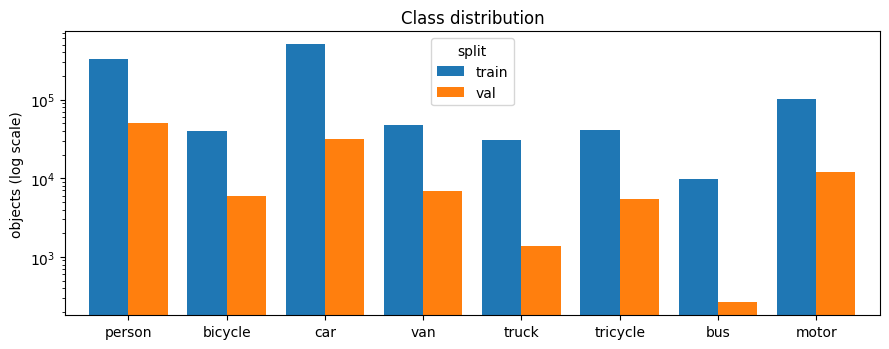

In [6]:
display(hd.class_distribution(objs))
hd.plot_class_distribution(objs);

Classes "person" and "car" are the most dominate in both train and validation data. Howewer, in train data there are slightly more observaltions of class car compared to person, while in validation data the distribution is opposite.

### 1.2 Object sizes and shapes

size_bin,tiny (<16),small (16-32),medium (32-96),large (>=96),median sqrt(area) px,median aspect h/w
class_name,,,,,,
person,3.8,33.8,61.7,0.7,36.700001,2.00
bicycle,2.9,18.8,75.6,2.8,43.900002,1.08
car,0.7,15.2,64.9,19.2,57.599998,0.79
van,0.2,19.2,63.8,16.7,51.299999,0.88
truck,0.0,9.1,57.5,33.4,73.900002,0.93
tricycle,0.6,20.1,65.3,14.0,54.500000,0.95
bus,0.0,4.0,39.4,56.6,111.699997,0.96
motor,4.1,27.3,66.9,1.7,39.799999,1.24


{'scaled sqrt(area) quantiles': {'q5': np.float64(14.1),
  'q25': np.float64(22.7),
  'q50': np.float64(31.8),
  'q75': np.float64(45.9),
  'q95': np.float64(86.1),
  'q99': np.float64(133.7)},
 'aspect h/w quantiles': {'q10': np.float64(0.48),
  'q50': np.float64(1.07),
  'q90': np.float64(2.28)},
 'share below 32 px after resize %': 50.4}

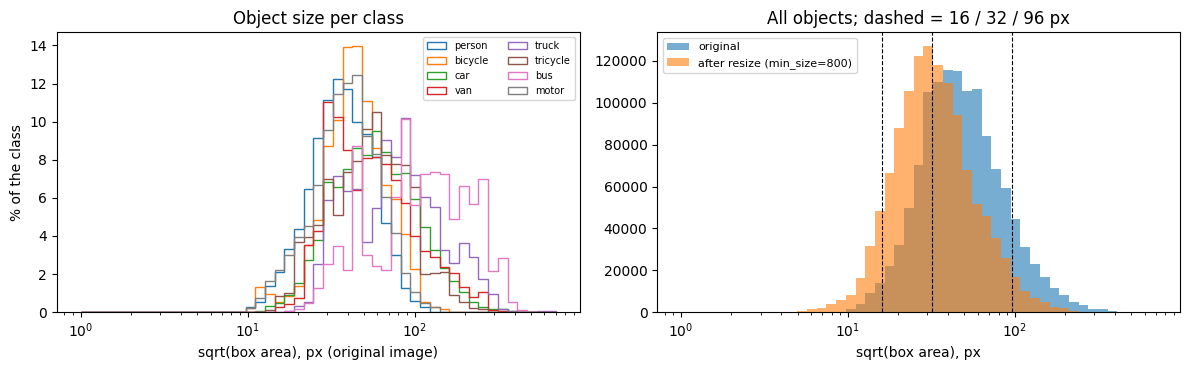

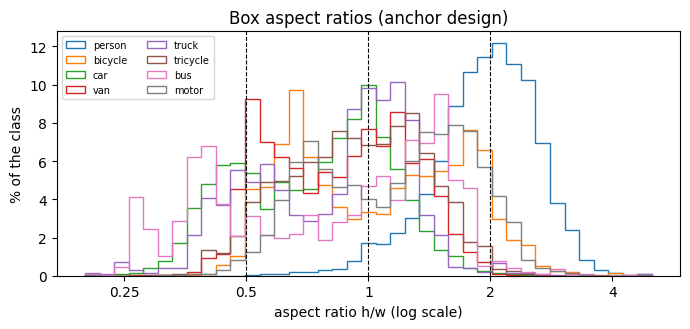

In [7]:
display(hd.size_table(objs))
hd.plot_size_distribution(objs, min_size=800, max_size=1333);
hd.plot_aspect_ratios(objs);
hd.suggest_anchor_stats(objs, min_size=800, max_size=1333)

Before resizing mean object size in pixels was **58.3** and after resizing the mean shrank to **31.8**

The share of tiny object (<16px) remains almost the same - ~5%.

Most of object's aspect ratio lies between 0.5 and 2 and have small left and right tails.
- Class *person* is mostly distributed at aspect ratio >2, which is normal as people normaly don't look like a square.
- Class *bus* is mostly distributed at aspect ration <0.25
- Classes *van* and *bicycke* have spickes at ~0.55 and ~0.7

The default anchor ratios (0.5, 1, 2) cover most objects well and only a few very tall people or very wide buses fall outside the range. Which is why we tune anchor sizes rather than shapes.

### 1.3 Scene density and variation across sequences

,split,frames,resolution,obj/frame mean,obj/frame max,frames with ignore %,median sqrt(area),tiny %,main class,main class %
clip,,,,,,,,,,
uav0000138_00000_v,train,213,2688x1512,143.0,156,100.0,45.400002,0.0,car,41.3
uav0000126_00001_v,train,412,2688x1512,132.2,166,100.0,48.400002,2.6,car,79.2
uav0000124_00944_v,train,398,2688x1512,124.6,134,100.0,46.299999,8.1,car,67.3
uav0000072_04488_v,train,85,1904x1071,110.4,124,0.0,45.799999,0.0,person,87.5
uav0000150_02310_v,train,348,2688x1512,108.9,174,75.0,60.000000,0.0,motor,34.6
...,...,...,...,...,...,...,...,...,...,...
uav0000117_02622_v,val,349,2720x1530,49.5,93,100.0,65.099998,1.4,person,56.0
uav0000182_00000_v,val,363,1344x756,48.7,87,95.0,32.400002,0.5,motor,33.3
uav0000339_00001_v,val,275,1904x1071,43.7,52,100.0,48.500000,0.0,person,45.6


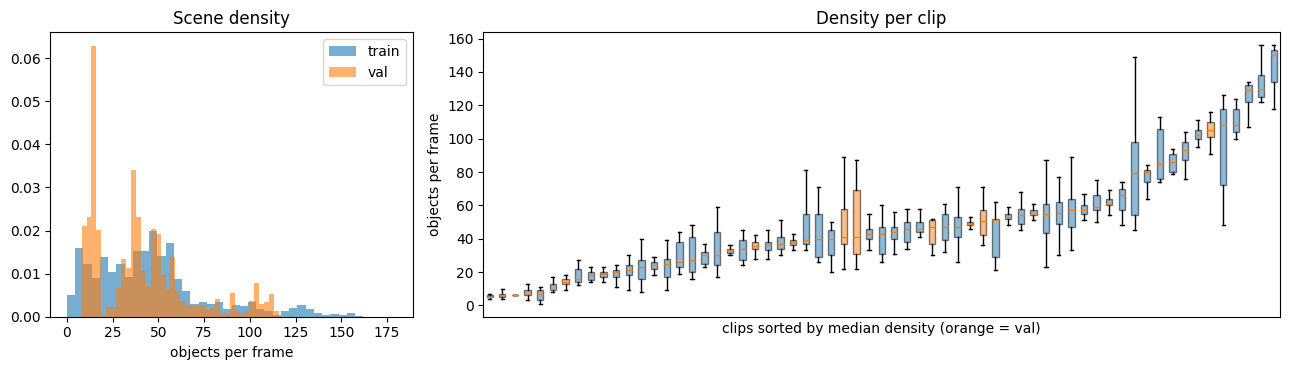

In [8]:
hd.plot_objects_per_frame(all_full);
clip_stats = hd.per_clip_stats(all_full, objs)
display(clip_stats)

**First table:**

In train data scene density is mostly distributed at range from 0 to 60 objects per frame with a tail up to 175 objects.

Validation data is more spiked and less dense. Most of data is at ~15 objects per frame and 30-60 objects per frame.

**Second table:**

Each box is a clip. Density is usually stable but some clips have very high min or max, which creates such long "whiskers".
Similarly to first table, validation clips are spreaded across table. The data includes both low, medium and high density clips.

Scene density ranges from almost empty frames to about 160 objects per frame. The density usually changes more between clips rather than inside on clip, which is why the data both train and validation data are splitted by clip in order to avoid leakage.

### 1.4 Ignored regions

In [9]:
display(pd.DataFrame({"train": hd.ignore_stats(train_full), "val": hd.ignore_stats(val_full)}))

,train,val
frames with ignored regions %,74.70,50.40
regions per frame (when present),3.50,2.80
mean image area covered % (approx.),2.41,1.62
GT boxes >50% inside ignore,11787.00,1199.00
GT boxes total,1105516.00,114132.00


### 1.5 Temporal redundancy (for the frame subsampling step)

In [10]:
redundancy = hd.temporal_redundancy(train_full, lags=(1, 2, 5, 10, 20, 40), n_clips=10, seed=SEED)
redundancy

,pixel_diff,box_persist
lag,,
1,8.305,0.955
2,10.712,0.798
5,16.456,0.394
10,20.241,0.214
20,23.316,0.107
40,25.748,0.098


`pixel_diff` — mean absolute grey-level difference between frame *t* and *t+lag*;
`box_persist` — share of objects at *t* that still have a same-class box with IoU > 0.5 at *t+lag*.

The best choice for train step is **lag 10**.
- lag 1-5 is too small as box persistance remains too high.
- lag 20+ adds too little information and removes too much training data.

So **lag 10** becomes a "golden mean" for `TRAIN_STEP`, as it has good box persistance and doesn't ignore too much data.

## 2. Preprocessing and validation protocol

### 2.1 Annotation conversion check
YOLO `cx cy w h` (normalised) → pixel `x1 y1 x2 y2`. Ground truth in class colours, ignored regions grey/hatched.

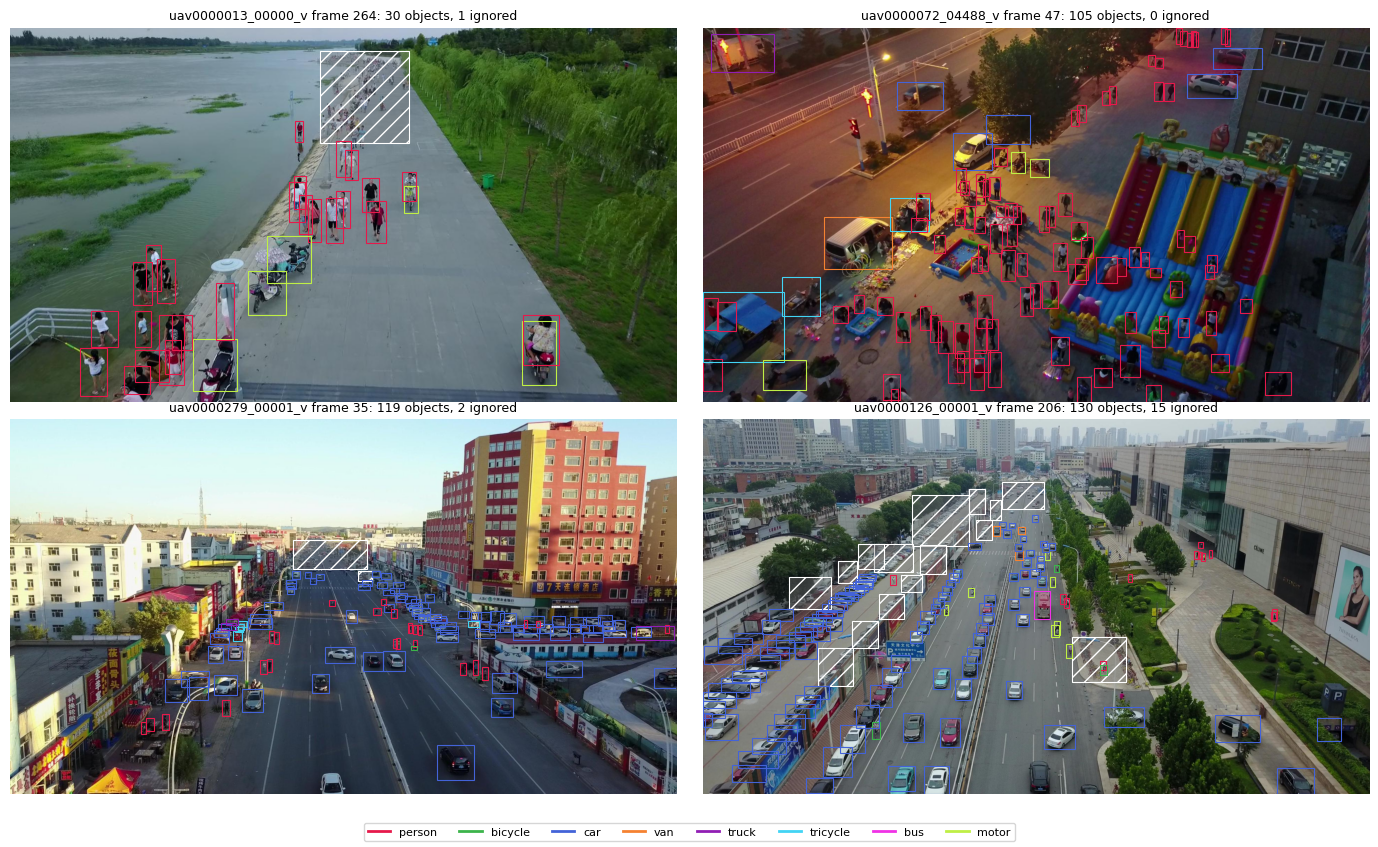

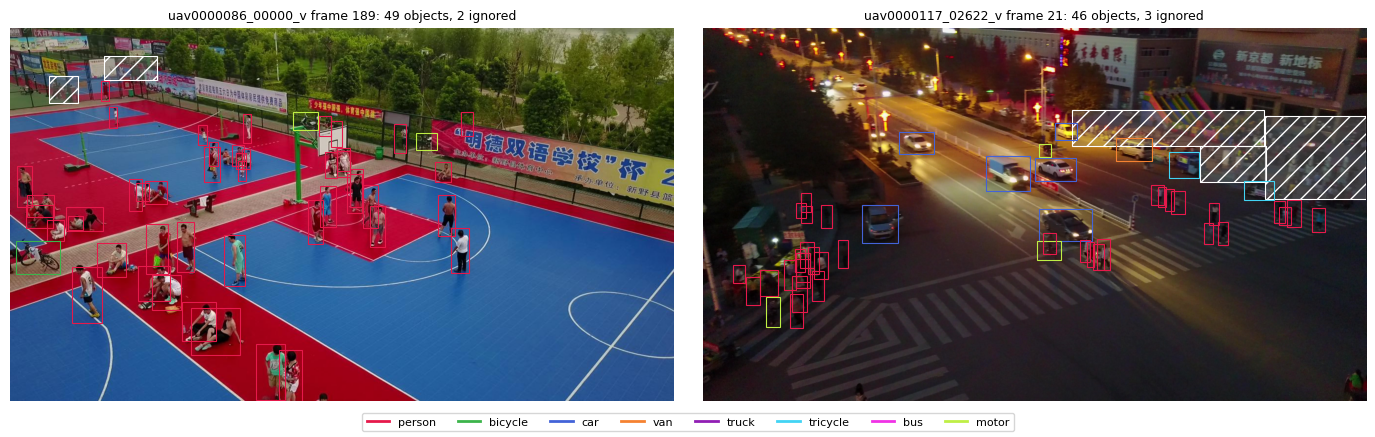

In [11]:
hd.show_gt_samples(train_full, n=4, seed=SEED);
hd.show_gt_samples(val_full, n=2, seed=SEED);

In [12]:
# compare the converted YOLO boxes with annotations_coco.json on random frames
coco_check = hd.crosscheck_with_coco(train_full, DATA_ROOT / "train" / "annotations_coco.json", n_frames=200, seed=SEED)
coco_check.describe().loc[["mean", "min", "max"]]

,yolo_boxes,coco_boxes,yolo_ignore,coco_crowd,mean_best_iou
mean,46.56,46.56,2.82,22.56,0.999959
min,3.00,3.00,0.00,0.00,0.999916
max,152.00,152.00,19.00,152.00,0.999984


In [13]:
# occlusion / truncation from the COCO file, used later in the failure analysis
try:
    val_full = hd.attach_coco_attributes(val_full, DATA_ROOT / "val" / "annotations_coco.json")
    print("val boxes matched to COCO attributes:", sum(int((o >= 0).sum()) for o in val_full["occlusion"]),
          "of", int(val_full["n_obj"].sum()))
except Exception as e:
    print("COCO attributes not attached:", repr(e))

val boxes matched to COCO attributes: 114132 of 114132


**Ignored regions and non-target classes.** VisDrone "ignored regions" and "others" are given only as
ignored regions (no class). During training they are painted with the mean colour and GT boxes lying
more than 50 % inside them are dropped, so the model is neither rewarded nor punished there. During
evaluation, detections lying more than 50 % inside an ignored region are removed before scoring (unless
they match an annotated box), which reproduces "detections there are not penalised".

### 2.2 Split and frame subsampling
The organisers' `val/` clips are a sequence-level hold-out (checked below). All model comparisons use the
same training frames, the same validation frames, the same metric code and the same seed.

In [14]:
print("clips in both train and val:", hd.check_clip_overlap(train_full, val_full) or "none")
train_df = hd.subsample_frames(train_full, TRAIN_STEP)
val_df = hd.subsample_frames(val_full, VAL_STEP)
print(f"train: {len(train_full)} -> {len(train_df)} frames | val: {len(val_full)} -> {len(val_df)} frames")
display(hd.class_distribution(hd.boxes_table(pd.concat([train_df, val_df], ignore_index=True))))

clips in both train and val: none
train: 24201 -> 151 frames | val: 2846 -> 60 frames


split,train,val,train %,val %
class_name,,,,
person,2266,1080,31.54,44.55
bicycle,275,130,3.83,5.36
car,3150,668,43.84,27.56
van,312,141,4.34,5.82
truck,194,27,2.70,1.11
tricycle,282,114,3.92,4.70
bus,63,6,0.88,0.25
motor,643,258,8.95,10.64


In [15]:
# optional: clip-level folds (GroupKFold) for later cross-validation of the final pipeline
folds = hd.make_clip_folds(train_full, n_splits=5, seed=SEED)
folds.groupby("fold").agg(clips=("clip", "nunique"), frames=("clip", "size"), objects=("n_obj", "sum"))

,clips,frames,objects
fold,,,
0,10,4830,160543
1,11,4844,170557
2,12,4876,288431
3,11,4787,259822
4,12,4864,226163


### 2.3 Resizing, normalisation, augmentation
* **Resize** (inside every model, same rule): shorter side → 800 px, longer side ≤ 1333 px, aspect ratio kept.
* **Normalisation**: torchvision models use ImageNet mean/std internally; RT-DETR uses 0–1 inputs (as its
  image processor does).
* **Augmentation** (training only): horizontal flip p = 0.5. Colour jitter is available but off in the protocol.
* Reproducibility: fixed seed, seeded DataLoader generator, the same subsampled frames for all models.

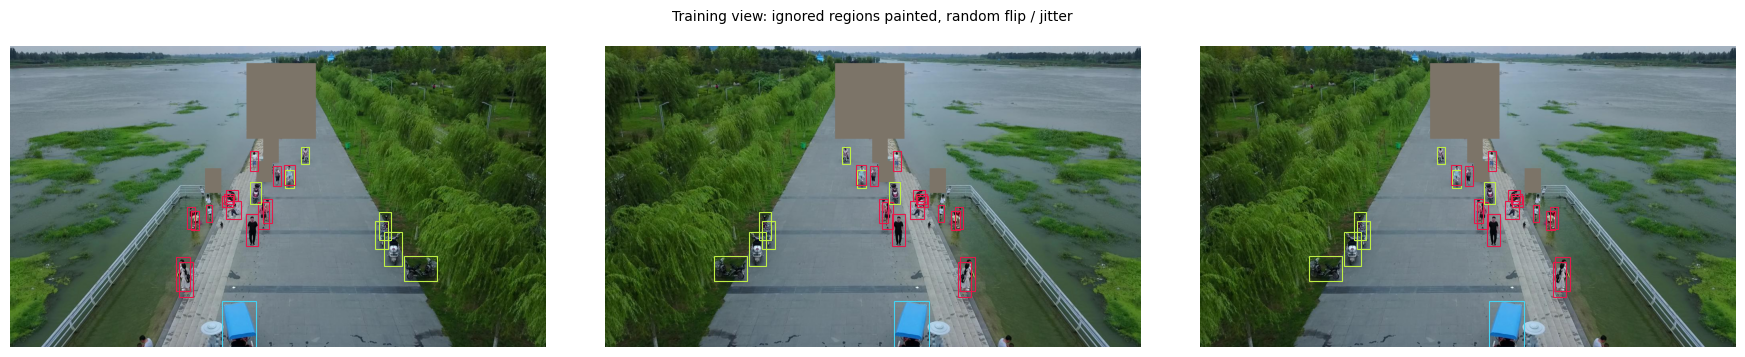

In [16]:
aug_ds = hd.DroneDetDataset(train_df, train=True, mask_ignore=True, hflip_p=0.5)
example = int(np.argmax(train_df["n_ignore"].to_numpy() > 0))  # a frame with ignored regions
hd.show_augmented(aug_ds, example, n=3, seed=SEED);

In [17]:
# shared protocol: every experiment = these settings + the changes listed in its section
PROTOCOL = dict(epochs=EPOCHS, train_step=TRAIN_STEP, val_step=VAL_STEP, max_minutes=MAX_MINUTES, seed=SEED,
                batch_size=BATCH_SIZE, grad_accum=GRAD_ACCUM, eval_batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
BASE = {arch: hd.make_config(arch, **PROTOCOL) for arch in hd.ARCH_DEFAULTS}
pd.Series({k: v for k, v in BASE["faster_rcnn"].items() if k in hd.COMMON_CFG}, dtype=object).to_frame("value")

,value
pretrained,True
seed,42
min_size,800
max_size,1333
train_step,200
val_step,50
mask_ignore,True
drop_ioa,0.5
hflip_p,0.5
color_jitter,0.0


In [18]:
def experiments(arch, **variants):
    # {run name: config}; each variant = BASE[arch] + its changes
    return {name: hd.make_config(arch, **PROTOCOL, **changes) for name, changes in variants.items()}


def run_or_load(exps, train=True):
    # train (or continue / load if finished) every experiment; returns {name: result}
    out = {}
    for name, cfg in exps.items():
        if train and TRAIN:
            out[name] = hd.run_experiment(name, cfg, train_df, val_df, RESULTS_DIR, EXTRA_RESULTS_DIRS, DEVICE)
        else:
            found = next((Path(d) / name for d in [RESULTS_DIR, *EXTRA_RESULTS_DIRS]
                          if (Path(d) / name / "metrics.json").exists()), None)
            if found is not None:
                out[name] = hd.load_run(found)
            else:
                print(f"[{name}] not trained yet")
    return out


def run_dir(name):
    for d in [RESULTS_DIR, *EXTRA_RESULTS_DIRS]:
        if (Path(d) / name / "metrics.json").exists():
            return Path(d) / name
    raise FileNotFoundError(name)


def best_of(results):
    return max(results.values(), key=lambda r: r["mAP"]) if results else None


def changes_table(exps):
    diffs = {n: {k: str(v) for k, v in hd.config_diff(c, BASE[c["arch"]]).items()} for n, c in exps.items()}
    return pd.DataFrame(diffs).T.fillna("")

## 3. Two-stage anchor-based: Faster R-CNN

`fasterrcnn_resnet50_fpn_v2` (torchvision), COCO-pretrained, new classifier for 8 classes.
Experiments are cumulative (each one keeps the previous change):

1. `frcnn_base` — default settings.
2. `frcnn_props` — more RPN proposals (dense scenes with 100+ objects; default keeps 1000 at test time).
3. `frcnn_props_giou` — + GIoU box regression loss in the second stage instead of smooth-L1.

In [19]:
PROPS = dict(rpn_pre_nms_top_n_train=3000, rpn_post_nms_top_n_train=3000,
             rpn_pre_nms_top_n_test=3000, rpn_post_nms_top_n_test=2000)
FRCNN_EXPS = experiments(
    "faster_rcnn",
    frcnn_base={},
    frcnn_props=PROPS,
    frcnn_props_giou={**PROPS, "box_loss": "giou"},
    # frcnn_props_roi={**PROPS, "box_batch_size_per_image": 1024, "box_positive_fraction": 0.5},  # optional
)
changes_table(FRCNN_EXPS)

,rpn_pre_nms_top_n_train,rpn_pre_nms_top_n_test,rpn_post_nms_top_n_train,rpn_post_nms_top_n_test,box_loss
frcnn_base,,,,,
frcnn_props,3000,3000,3000,2000,
frcnn_props_giou,3000,3000,3000,2000,giou


In [20]:
frcnn_res = run_or_load(FRCNN_EXPS, train=RUN["faster_rcnn"])
hd.results_table(list(frcnn_res.values())) if frcnn_res else None

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:00<00:00, 201MB/s]


[frcnn_base] epoch 1/1 loss 1.8895 | val mAP 0.0579 AP50 0.1439 AP_small 0.0481 | 0.7 min
[frcnn_base] done: mAP 0.0579 | AP50 0.1439 | AP_small 0.0481 | 15.01 img/s | 0.6 min
[frcnn_props] epoch 1/1 loss 1.9291 | val mAP 0.0563 AP50 0.1426 AP_small 0.0429 | 0.6 min
[frcnn_props] done: mAP 0.0563 | AP50 0.1426 | AP_small 0.0429 | 11.04 img/s | 0.4 min
[frcnn_props_giou] epoch 1/1 loss 1.3241 | val mAP 0.0333 AP50 0.1067 AP_small 0.0341 | 0.6 min
[frcnn_props_giou] done: mAP 0.0333 | AP50 0.1067 | AP_small 0.0341 | 10.73 img/s | 0.4 min


,arch,mAP,AP50,AP75,AP_tiny,AP_small,AP_medium,AP_large,AR,ms_per_img,fps,params_M,train_minutes,best_epoch
run,,,,,,,,,,,,,,
frcnn_base,faster_rcnn,0.0579,0.1439,0.0371,0.0252,0.0481,0.0553,0.1129,0.1745,66.6,15.01,43.29,0.6,1
frcnn_props,faster_rcnn,0.0563,0.1426,0.0320,0.0220,0.0429,0.0552,0.1043,0.1564,90.6,11.04,43.29,0.4,1
frcnn_props_giou,faster_rcnn,0.0333,0.1067,0.0044,0.0014,0.0341,0.0353,0.0511,0.1162,93.2,10.73,43.29,0.4,1


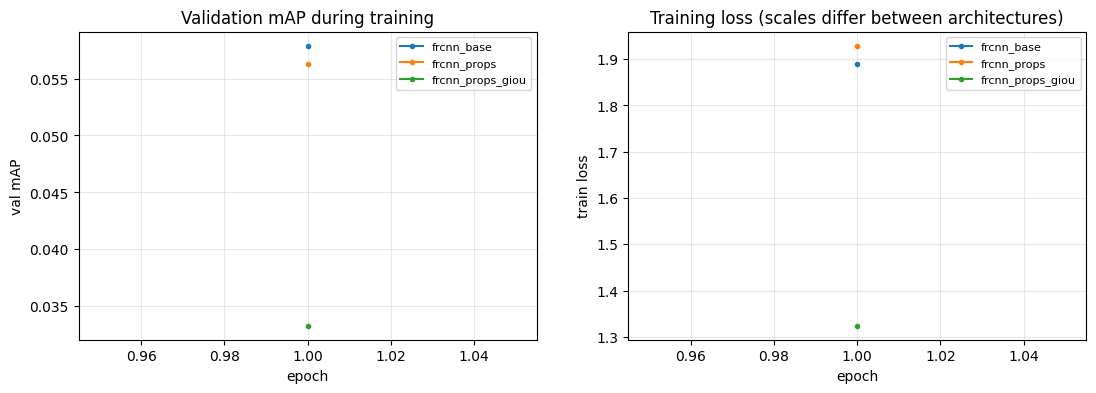

,frcnn_base,frcnn_props,frcnn_props_giou
person,0.1331,0.1205,0.0998
bicycle,0.0054,0.0033,0.0007
car,0.2610,0.2629,0.1159
van,0.0002,0.0001,0.0002
truck,0.0000,0.0000,0.0000
tricycle,0.0078,0.0091,0.0101
bus,0.0000,0.0000,0.0000
motor,0.0555,0.0545,0.0397


In [21]:
if frcnn_res:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    hd.plot_histories({n: r.get("history") for n, r in frcnn_res.items()}, ax=axes[0])
    hd.plot_train_losses({n: r.get("history") for n, r in frcnn_res.items()}, ax=axes[1])
    plt.show()
    display(hd.per_class_table(list(frcnn_res.values())))

### 3.1 What the two stages contribute
For each GT box: is it covered (IoU ≥ 0.5) by the top-N RPN proposals, and by the final detections?
`best_iou_*` shows how much the second stage refines localisation.

In [22]:
FRCNN_BEST = best_of(frcnn_res)["name"] if frcnn_res else None
if FRCNN_BEST and MODEL_ANALYSIS:
    frcnn_model = hd.load_model_from_run(run_dir(FRCNN_BEST), DEVICE)
    display(hd.rpn_proposal_recall(frcnn_model, val_df, DEVICE, n_images=100, top_ns=(100, 300, 1000, 2000)))
    del frcnn_model
    torch.cuda.empty_cache()

/usr/local/lib/python3.13/dist-packages/torchvision/models/detection/backbone_utils.py:162: UserWarning: Changing trainable_backbone_layers has no effect if neither pretrained nor pretrained_backbone have been set to True, falling back to trainable_backbone_layers=5 so that all layers are trainable
  warnings.warn(


,objects,proposals@100,proposals@300,proposals@1000,proposals@2000,best_iou_proposal,final (any class),final (correct class),best_iou_final
size_bin,,,,,,,,,
tiny (<16),8,0.125,0.250,0.250,0.250,0.200,0.250,0.125,0.199
small (16-32),467,0.516,0.657,0.660,0.660,0.547,0.634,0.542,0.524
medium (32-96),1686,0.637,0.780,0.806,0.806,0.660,0.769,0.660,0.627
large (>=96),263,0.856,0.973,1.000,1.000,0.845,0.977,0.768,0.794
all,2424,0.636,0.776,0.797,0.797,0.657,0.764,0.647,0.624


*Observations (fill in):* recall of proposals vs. final detections by object size; what does stage 2 add / lose?

### 3.2 Failure cases
Error types at score ≥ 0.3: missed objects, background false positives, wrong class, poor localisation, duplicates.
Green = correct, red = false positive, yellow dashed = missed, grey = ignored region.

In [23]:
def failure_report(name, score_thr=0.3):
    preds = hd.load_val_preds(run_dir(name))
    gt_tab, pr_tab, conf = hd.analyze_failures(val_df, preds, score_thr=score_thr)
    for title, tab in hd.failure_summary(gt_tab, pr_tab).items():
        print("--", title)
        display(tab)
    print("-- class confusions (rows = GT, columns = prediction)")
    display(conf)
    return preds, gt_tab, pr_tab


if FRCNN_BEST:
    frcnn_preds, frcnn_gt_tab, frcnn_pr_tab = failure_report(FRCNN_BEST)

-- recall by size


,size,mean
size_bin,,
tiny (<16),8,0.000
small (16-32),467,0.210
medium (32-96),1686,0.257
large (>=96),263,0.506


-- recall by class


,size,mean
class_name,,
bicycle,130,0.000
bus,6,0.000
car,668,0.651
motor,258,0.000
person,1080,0.213
tricycle,114,0.000
truck,27,0.000
van,141,0.000


-- recall by density


,size,mean
density,,
"[0.0, 50.0)",1080,0.272
"[50.0, 100.0)",814,0.230
"[100.0, 200.0)",530,0.347


... (2 outputs left out)

-- recall by occlusion


,size,mean
occlusion,,
0,989,0.377
1,1275,0.217
2,160,0.094


-- class confusions (rows = GT, columns = prediction)


,pred person,pred bicycle,pred car,pred van,pred truck,pred tricycle,pred bus,pred motor
GT person,0,0,2,0,0,0,0,0
GT bicycle,7,0,6,0,0,0,0,0
GT car,0,0,0,0,0,0,0,0
GT van,0,0,113,0,0,0,0,0
GT truck,0,0,17,0,0,0,0,0
GT tricycle,4,0,49,0,0,0,0,0
GT bus,0,0,4,0,0,0,0,0
GT motor,40,0,16,0,0,0,0,0


/content/repo/hw2_detection.py:1942: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


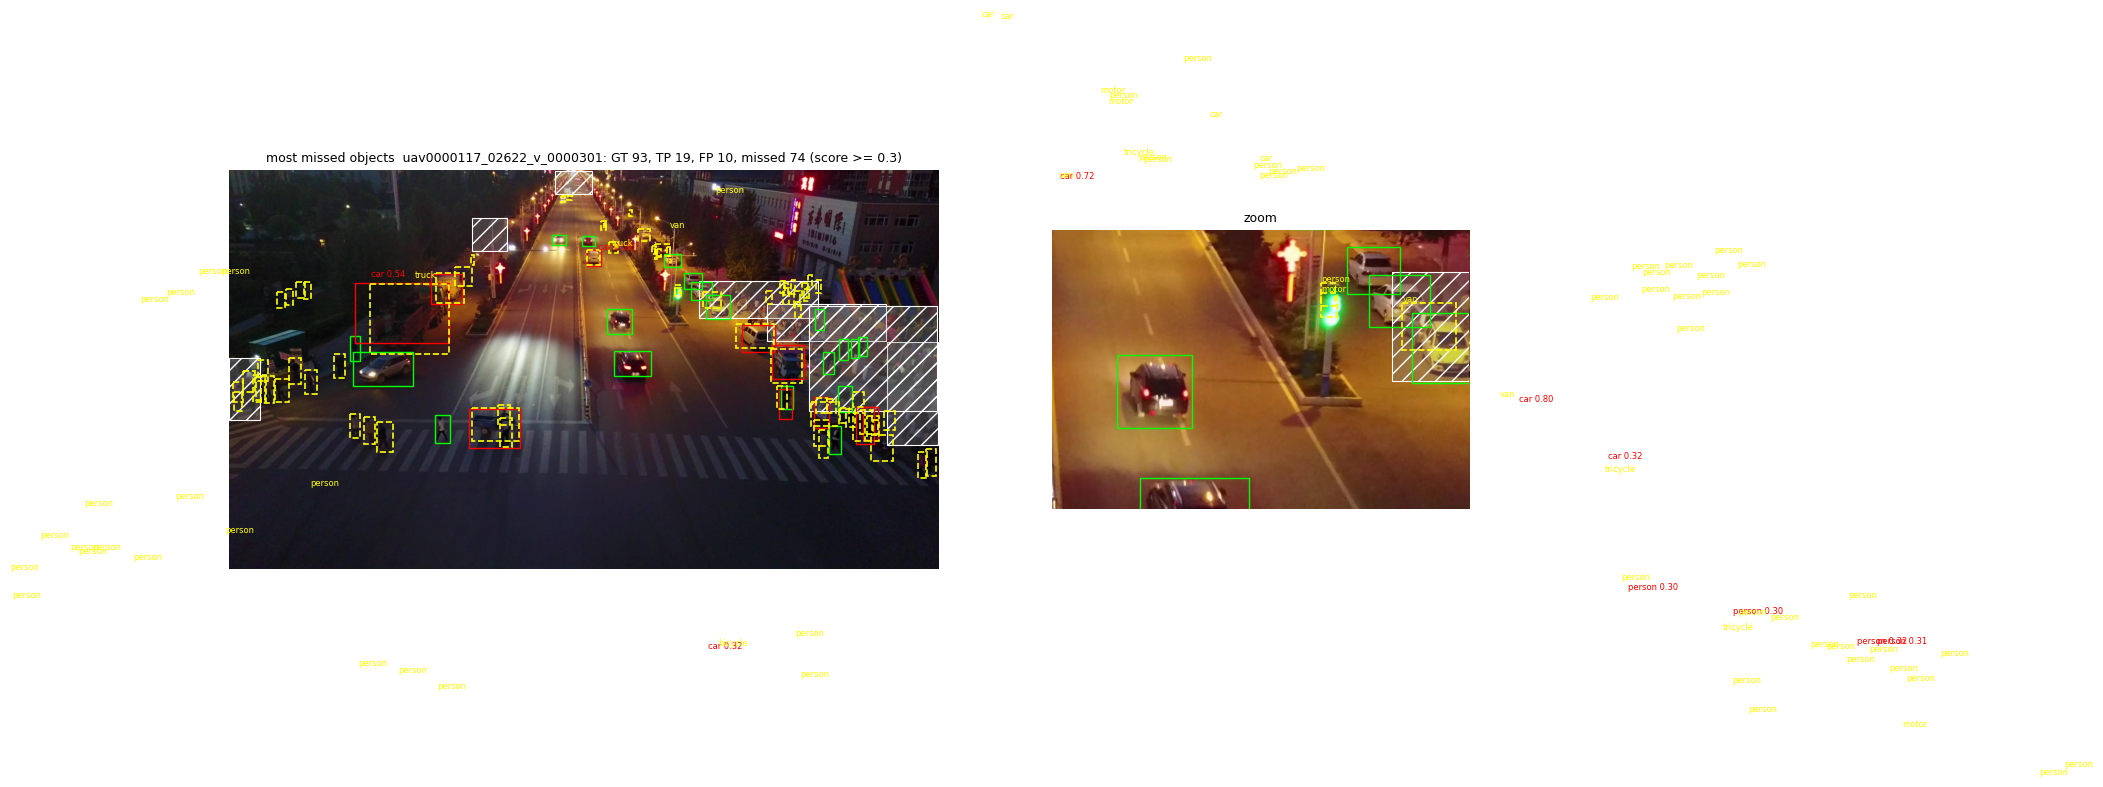

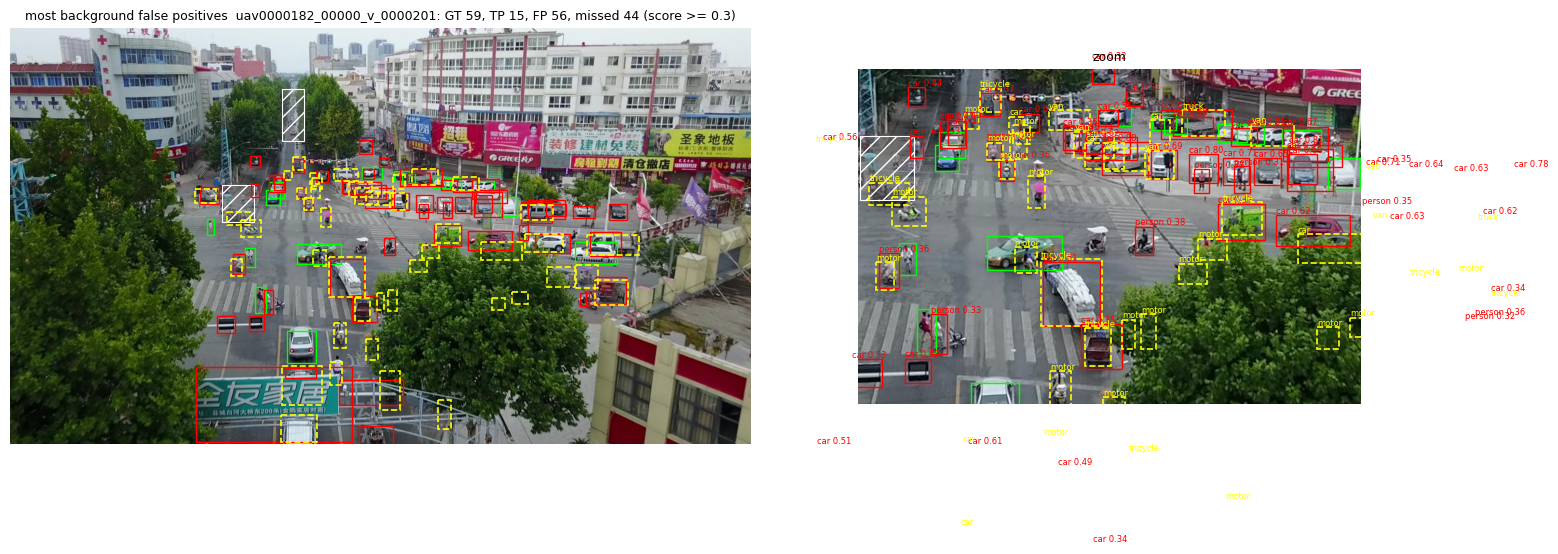

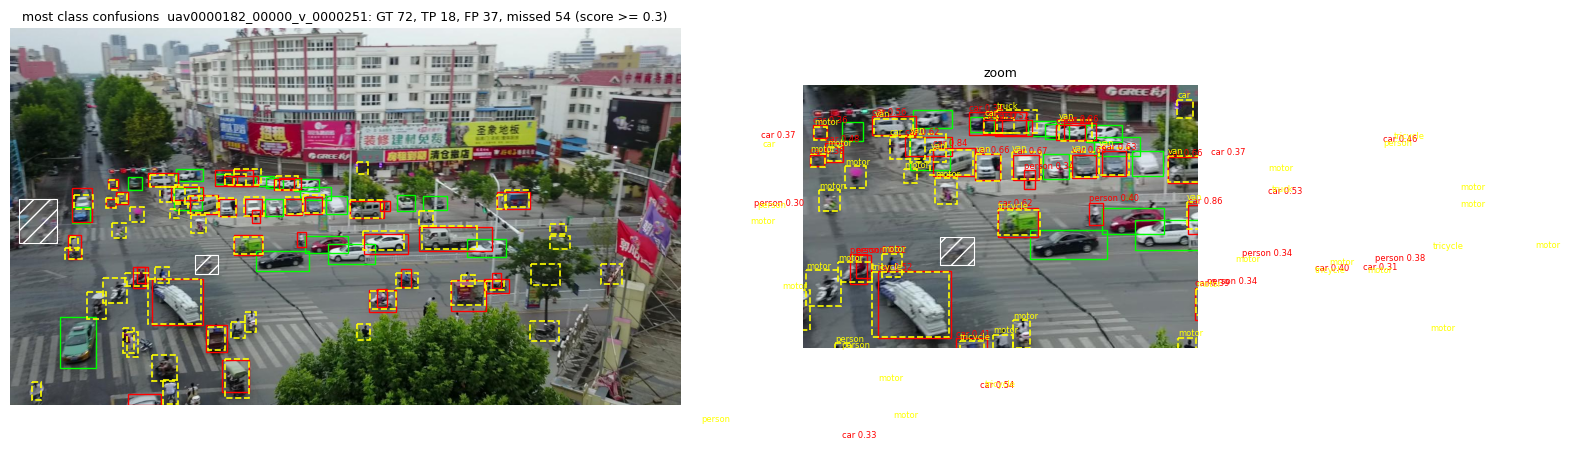

In [24]:
if FRCNN_BEST:
    for title, rows in hd.pick_failure_frames(frcnn_gt_tab, frcnn_pr_tab, n_each=1).items():
        for row in rows:
            hd.plot_failure_frame(val_df, frcnn_preds, row, score_thr=0.3, title=title)
            plt.show()

*Failure cases (fill in, at least three):* for each frame above — what went wrong and the plausible cause
(object size, occlusion, density, similar classes, motion blur, ...), backed by the tables above.

## 4. One-stage anchor-based: RetinaNet

`retinanet_resnet50_fpn_v2` (torchvision), COCO-pretrained, same protocol.
First check how well anchor sets match the object sizes from section 1 (after resize).

In [25]:
DEFAULT_ANCHORS = hd.retinanet_anchor_sizes((32, 64, 128, 256, 512))
SMALL_ANCHORS = hd.retinanet_anchor_sizes((16, 32, 64, 128, 256))   # chosen from section 1.2
RATIOS = (0.5, 1.0, 2.0)
flat = lambda sizes: [s for level in sizes for s in level]
print("default:", DEFAULT_ANCHORS)
print("small  :", SMALL_ANCHORS)
pd.concat({"default anchors": hd.anchor_coverage(objs, flat(DEFAULT_ANCHORS), RATIOS),
           "small anchors": hd.anchor_coverage(objs, flat(SMALL_ANCHORS), RATIOS)}, axis=1)

default: ((32, 40, 50), (64, 80, 101), (128, 161, 203), (256, 322, 406), (512, 645, 812))
small  : ((16, 20, 25), (32, 40, 50), (64, 80, 101), (128, 161, 203), (256, 322, 406))


default anchors                           small anchors                          
                       objects mean_best_iou covered_pct       objects mean_best_iou covered_pct
size_bin                                                                                        
large (>=96)          140980.0         0.829        99.8      140980.0         0.829        99.8
medium (32-96)        781382.0         0.744        90.4      781382.0         0.826        99.9
small (16-32)         272954.0         0.407        24.8      272954.0         0.790        95.4
tiny (<16)             24332.0         0.138         0.0       24332.0         0.536        55.2
all                  1219648.0         0.667        75.0     1219648.0         0.812        98.0

`covered_pct` = share of GT boxes whose best anchor shape reaches IoU ≥ 0.5 (the positive threshold),
centres aligned — an upper bound for the real assignment.

In [26]:
RETINA_EXPS = experiments(
    "retinanet",
    retina_base={},
    retina_anchors={"anchor_base_sizes": (16, 32, 64, 128, 256)},
    retina_anchors_focal={"anchor_base_sizes": (16, 32, 64, 128, 256), "focal_gamma": 1.5},
)
changes_table(RETINA_EXPS)

,anchor_base_sizes,focal_gamma
retina_base,,
retina_anchors,"(16, 32, 64, 128, 256)",
retina_anchors_focal,"(16, 32, 64, 128, 256)",1.5


Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth


100%|██████████| 146M/146M [00:01<00:00, 126MB/s]


[retina_base] epoch 1/1 loss 1.2932 | val mAP 0.0011 AP50 0.0015 AP_small 0.0000 | 0.5 min
[retina_base] done: mAP 0.0011 | AP50 0.0015 | AP_small 0.0000 | 18.12 img/s | 0.4 min
[retina_anchors] epoch 1/1 loss 1.5581 | val mAP 0.0003 AP50 0.0010 AP_small 0.0000 | 0.5 min
[retina_anchors] done: mAP 0.0003 | AP50 0.0010 | AP_small 0.0000 | 18.2 img/s | 0.3 min
[retina_anchors_focal] epoch 1/1 loss 1.6545 | val mAP 0.0008 AP50 0.0030 AP_small 0.0002 | 0.4 min
[retina_anchors_focal] done: mAP 0.0008 | AP50 0.0030 | AP_small 0.0002 | 15.94 img/s | 0.3 min


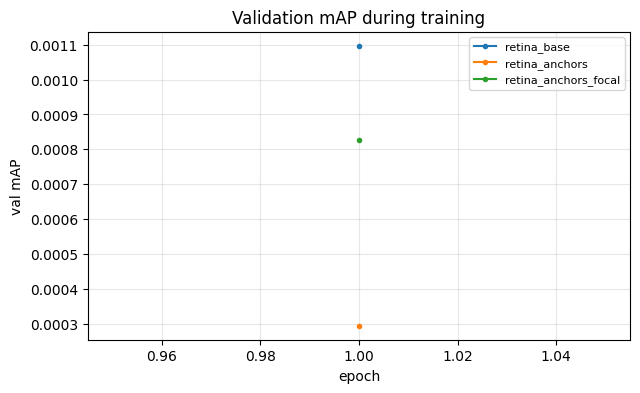

,arch,mAP,AP50,AP75,AP_tiny,AP_small,AP_medium,AP_large,AR,ms_per_img,fps,params_M,train_minutes,best_epoch
run,,,,,,,,,,,,,,
retina_base,retinanet,0.0011,0.0015,0.0013,0.0000,0.0000,0.0006,0.0064,0.0274,55.2,18.12,36.48,0.4,1
retina_anchors,retinanet,0.0003,0.0010,0.0000,0.0000,0.0000,0.0002,0.0008,0.0106,54.9,18.20,36.48,0.3,1
retina_anchors_focal,retinanet,0.0008,0.0030,0.0001,0.0000,0.0002,0.0006,0.0024,0.0051,62.7,15.94,36.48,0.3,1
frcnn_base,faster_rcnn,0.0579,0.1439,0.0371,0.0252,0.0481,0.0553,0.1129,0.1745,66.6,15.01,43.29,0.6,1


In [27]:
retina_res = run_or_load(RETINA_EXPS, train=RUN["retinanet"])
if retina_res:
    hd.plot_histories({n: r.get("history") for n, r in retina_res.items()})
    plt.show()
compare = list(retina_res.values()) + ([frcnn_res[FRCNN_BEST]] if FRCNN_BEST else [])
hd.results_table(compare) if compare else None

*Discussion (fill in):* what can go wrong without a proposal stage (e.g. extreme foreground/background
imbalance over ~100k anchors, no second refinement step) and how RetinaNet addresses it (focal loss,
IoU thresholds, anchor design). Initial vs tuned RetinaNet vs tuned Faster R-CNN.

## 5. One-stage anchor-free: FCOS

`FCOS ResNet-50-FPN` (torchvision), COCO-pretrained. Every feature-map point is a candidate; it is positive
for a box if it lies inside the box, near its centre (`center_sampling_radius × stride`) and the box size fits
the FPN level. The simulation below counts positive locations per GT box for different settings.

In [28]:
assign = {}
for label, strides, radius in [("P3-P7, r=1.5 (default)", hd.fcos_strides(False), 1.5),
                               ("P3-P7, r=2.5", hd.fcos_strides(False), 2.5),
                               ("P2-P7, r=1.5", hd.fcos_strides(True), 1.5)]:
    tab, summary = hd.fcos_assignment_stats(train_df, strides=strides, center_radius=radius, n_images=300, seed=SEED)
    assign[label] = tab
    print(label, summary)
pd.concat(assign, axis=1)

P3-P7, r=1.5 (default) {'strides': [8, 16, 32, 64, 128], 'center_radius': 1.5, 'GT without any positive location %': 1.11, 'ambiguous locations (claimed by >1 box) %': 6.45}
P3-P7, r=2.5 {'strides': [8, 16, 32, 64, 128], 'center_radius': 2.5, 'GT without any positive location %': 0.92, 'ambiguous locations (claimed by >1 box) %': 8.77}
P2-P7, r=1.5 {'strides': [4, 8, 16, 32, 64, 128], 'center_radius': 1.5, 'GT without any positive location %': 0.26, 'ambiguous locations (claimed by >1 box) %': 2.97}


P3-P7, r=1.5 (default)                                                          P3-P7, r=2.5                                                          P2-P7, r=1.5                     \
                              objects mean_pos_locations no_positive_pct lost_to_other_box_pct      objects mean_pos_locations no_positive_pct lost_to_other_box_pct      objects mean_pos_locations   
size_bin                                                                                                                                                                                               
tiny (<16)                        160               2.08           11.25                  5.62          160               2.08           11.25                  5.62          160               6.40   
small (16-32)                    1592               5.01            1.76                 12.94         1592               6.02            1.70                 13.88         1592               8.29   
medium (32-96)                   4618               7.71            0.71                 21.03         4618              14.80            0.45                 31.94         4618               9.76   
large (>=96)                      815              10.08            0.12                  6.26          815              26.86            0.00                 20.25          815              10.36   

                                                      
               no_positive_pct lost_to_other_box_pct  
size_bin                                              
tiny (<16)                1.88                  8.75  
small (16-32)             0.57                 10.11  
medium (32-96)            0.15                 10.13  
large (>=96)              0.00                  5.64

In [29]:
FCOS_EXPS = experiments(
    "fcos",
    fcos_base={},
    fcos_p2={"p2_level": True},                       # extra high-resolution level (stride 4)
    fcos_p2_ciou={"p2_level": True, "box_loss": "ciou"},
)
changes_table(FCOS_EXPS)

,p2_level,box_loss
fcos_base,,
fcos_p2,True,
fcos_p2_ciou,True,ciou


Downloading: "https://download.pytorch.org/models/fcos_resnet50_fpn_coco-99b0c9b7.pth" to /root/.cache/torch/hub/checkpoints/fcos_resnet50_fpn_coco-99b0c9b7.pth


100%|██████████| 124M/124M [00:00<00:00, 252MB/s]


[fcos_base] epoch 1/1 loss 1.6047 | val mAP 0.0820 AP50 0.1627 AP_small 0.0594 | 0.7 min
[fcos_base] done: mAP 0.0820 | AP50 0.1627 | AP_small 0.0594 | 12.85 img/s | 0.5 min
FCOS-P2: new (randomly initialised) tensors: 4, unused: 0
[fcos_p2] epoch 1/1 loss 1.7841 | val mAP 0.0609 AP50 0.1095 AP_small 0.0308 | 1.1 min
[fcos_p2] done: mAP 0.0609 | AP50 0.1095 | AP_small 0.0308 | 7.09 img/s | 0.9 min
FCOS-P2: new (randomly initialised) tensors: 4, unused: 0
[fcos_p2_ciou] epoch 1/1 loss 1.7733 | val mAP 0.0561 AP50 0.0997 AP_small 0.0296 | 1.0 min
[fcos_p2_ciou] done: mAP 0.0561 | AP50 0.0997 | AP_small 0.0296 | 7.08 img/s | 0.8 min


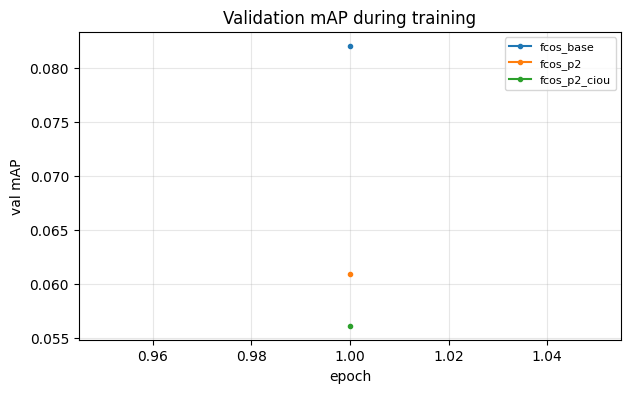

,arch,mAP,AP50,AP_tiny,AP_small,AP_medium,AP_large,AR,fps
run,,,,,,,,,
fcos_base,fcos,0.0820,0.1627,0.0000,0.0594,0.0772,0.1605,0.1975,12.85
fcos_p2,fcos,0.0609,0.1095,0.0000,0.0308,0.0601,0.1145,0.1853,7.09
fcos_p2_ciou,fcos,0.0561,0.0997,0.0000,0.0296,0.0522,0.1130,0.1835,7.08
frcnn_base,faster_rcnn,0.0579,0.1439,0.0252,0.0481,0.0553,0.1129,0.1745,15.01
retina_base,retinanet,0.0011,0.0015,0.0000,0.0000,0.0006,0.0064,0.0274,18.12


In [30]:
fcos_res = run_or_load(FCOS_EXPS, train=RUN["fcos"])
if fcos_res:
    hd.plot_histories({n: r.get("history") for n, r in fcos_res.items()})
    plt.show()
compare = list(fcos_res.values()) + [r for r in (best_of(frcnn_res), best_of(retina_res)) if r]
hd.results_table(compare, cols=["mAP", "AP50", "AP_tiny", "AP_small", "AP_medium", "AP_large", "AR", "fps"]) if compare else None

*Observations (fill in):* search range and selected settings; effect of P2 / loss on tiny and small objects
and on dense frames; comparison with the tuned anchor-based models by object size.

## 6. Query-based: RT-DETR

`PekingU/rtdetr_r50vd` (Hugging Face), COCO-pretrained, same resize rule, same epochs. AdamW,
backbone learning rate × 0.1. The number of queries is the maximum number of objects the model can output
per image, so it is compared with the scene density first.

In [31]:
print("objects per frame quantiles (train):")
print(train_full["n_obj"].quantile([0.5, 0.9, 0.99, 1.0]).round(0).to_dict())

objects per frame quantiles (train):
{0.5: 43.0, 0.9: 92.0, 0.99: 142.0, 1.0: 180.0}


In [32]:
RTDETR_EXPS = experiments(
    "rtdetr",
    rtdetr_base={},
    rtdetr_q500={"num_queries": 500},
    rtdetr_q500_giou={"num_queries": 500, "matcher_giou_cost": 4.0, "weight_loss_giou": 4.0},
)
changes_table(RTDETR_EXPS)

,num_queries,matcher_giou_cost,weight_loss_giou
rtdetr_base,,,
rtdetr_q500,500,,
rtdetr_q500_giou,500,4.0,4.0


In [33]:
rtdetr_res = run_or_load(RTDETR_EXPS, train=RUN["rtdetr"])
hd.results_table(list(rtdetr_res.values())) if rtdetr_res else None

config.json:   0%|          | 0.00/5.11k [00:00<?, ?B/s]

[transformers] You passed `num_labels=8` which is incompatible to the `id2label` map of length `80`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  172MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/764 [00:00<?, ?it/s]

[transformers] RTDetrForObjectDetection LOAD REPORT from: PekingU/rtdetr_r50vd
Key                                                 | Status   |                                                                                        
----------------------------------------------------+----------+----------------------------------------------------------------------------------------
model.enc_score_head.weight                         | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([80, 256]) vs model:torch.Size([8, 256])
model.denoising_class_embed.weight                  | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([81, 256]) vs model:torch.Size([9, 256])
model.decoder.class_embed.{0, 1, 2, 3, 4, 5}.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([80, 256]) vs model:torch.Size([8, 256])
model.decoder.class_embed.{0, 1, 2, 3, 4, 5}.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([80]) vs model:torch.Size([8])          
mod

... (6 outputs left out)

Loading weights:   0%|          | 0/764 [00:00<?, ?it/s]

[transformers] RTDetrForObjectDetection LOAD REPORT from: PekingU/rtdetr_r50vd
Key                                                 | Status   |                                                                                        
----------------------------------------------------+----------+----------------------------------------------------------------------------------------
model.enc_score_head.weight                         | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([80, 256]) vs model:torch.Size([8, 256])
model.denoising_class_embed.weight                  | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([81, 256]) vs model:torch.Size([9, 256])
model.decoder.class_embed.{0, 1, 2, 3, 4, 5}.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([80, 256]) vs model:torch.Size([8, 256])
model.decoder.class_embed.{0, 1, 2, 3, 4, 5}.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([80]) vs model:torch.Size([8])          
mod

[rtdetr_q500_giou] epoch 1/1 loss 76.4946 | val mAP 0.0132 AP50 0.0279 AP_small 0.0069 | 0.7 min
[rtdetr_q500_giou] done: mAP 0.0132 | AP50 0.0279 | AP_small 0.0069 | 12.66 img/s | 0.6 min


,arch,mAP,AP50,AP75,AP_tiny,AP_small,AP_medium,AP_large,AR,ms_per_img,fps,params_M,train_minutes,best_epoch
run,,,,,,,,,,,,,,
rtdetr_base,rtdetr,0.0102,0.0216,0.0090,0.0,0.0047,0.0112,0.0262,0.0555,83.1,12.03,42.74,0.7,1
rtdetr_q500,rtdetr,0.0104,0.0216,0.0090,0.0,0.0057,0.0108,0.0247,0.0400,79.9,12.51,42.74,0.6,1
rtdetr_q500_giou,rtdetr,0.0132,0.0279,0.0114,0.0,0.0069,0.0125,0.0305,0.0473,79.0,12.66,42.74,0.6,1


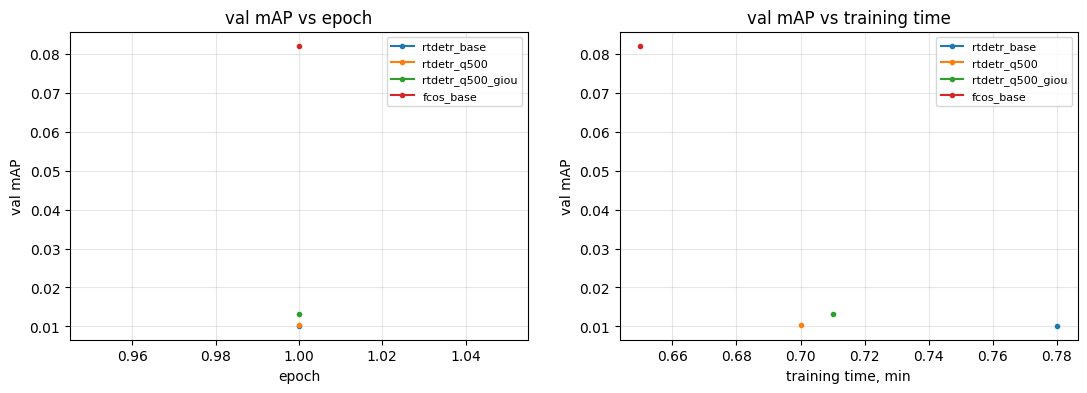

In [34]:
CNN_BEST = best_of({**frcnn_res, **retina_res, **fcos_res})
if rtdetr_res and CNN_BEST:
    curves = {**{n: r.get("history") for n, r in rtdetr_res.items()}, CNN_BEST["name"]: CNN_BEST.get("history")}
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    hd.plot_histories(curves, x="epoch", ax=axes[0], title="val mAP vs epoch")
    hd.plot_histories(curves, x="minutes", ax=axes[1], title="val mAP vs training time")
    plt.show()

In [35]:
# small objects and dense scenes: RT-DETR vs the best CNN on the same frames
if rtdetr_res and CNN_BEST:
    RTDETR_BEST = best_of(rtdetr_res)["name"]
    dens = {}
    for name in (RTDETR_BEST, CNN_BEST["name"]):
        dens[name] = hd.ap_by_density(val_df, hd.load_val_preds(run_dir(name)), bins=(0, 50, 100, 200, np.inf))
    display(pd.concat(dens, axis=1))
    display(hd.results_table([rtdetr_res[RTDETR_BEST], CNN_BEST],
                             cols=["mAP", "AP50", "AP_tiny", "AP_small", "AP_medium", "AP_large", "AR", "fps"]))

rtdetr_q500_giou                                         fcos_base                                        
                         frames       mAP      AP50  AP_small        AR    frames       mAP      AP50  AP_small        AR
objects/frame                                                                                                            
[0.0, 50.0)                  42  0.012509  0.024880  0.002128  0.045412        42  0.074735  0.141039  0.070356  0.203258
[50.0, 100.0)                13  0.013139  0.031083  0.013842  0.052655        13  0.094176  0.200751  0.065671  0.192726
[100.0, 200.0)                5  0.031607  0.068033  0.000000  0.065976         5  0.185971  0.366333  0.000000  0.277348

,arch,mAP,AP50,AP_tiny,AP_small,AP_medium,AP_large,AR,fps
run,,,,,,,,,
rtdetr_q500_giou,rtdetr,0.0132,0.0279,0.0,0.0069,0.0125,0.0305,0.0473,12.66
fcos_base,fcos,0.0820,0.1627,0.0,0.0594,0.0772,0.1605,0.1975,12.85


*Observations (fill in):* how bipartite matching replaces NMS and what it changes in training; has the model
converged within the budget; small objects and dense scenes vs the CNN.

## 7. Comparison of all models

,arch,mAP,AP50,AP75,AP_tiny,AP_small,AP_medium,AP_large,AR,ms_per_img,fps,params_M,train_minutes,best_epoch
run,,,,,,,,,,,,,,
frcnn_base,faster_rcnn,0.0579,0.1439,0.0371,0.0252,0.0481,0.0553,0.1129,0.1745,66.6,15.01,43.29,0.6,1
frcnn_props,faster_rcnn,0.0563,0.1426,0.0320,0.0220,0.0429,0.0552,0.1043,0.1564,90.6,11.04,43.29,0.4,1
frcnn_props_giou,faster_rcnn,0.0333,0.1067,0.0044,0.0014,0.0341,0.0353,0.0511,0.1162,93.2,10.73,43.29,0.4,1
retina_base,retinanet,0.0011,0.0015,0.0013,0.0000,0.0000,0.0006,0.0064,0.0274,55.2,18.12,36.48,0.4,1
retina_anchors,retinanet,0.0003,0.0010,0.0000,0.0000,0.0000,0.0002,0.0008,0.0106,54.9,18.20,36.48,0.3,1
retina_anchors_focal,retinanet,0.0008,0.0030,0.0001,0.0000,0.0002,0.0006,0.0024,0.0051,62.7,15.94,36.48,0.3,1
fcos_base,fcos,0.0820,0.1627,0.0729,0.0000,0.0594,0.0772,0.1605,0.1975,77.8,12.85,32.08,0.5,1
fcos_p2,fcos,0.0609,0.1095,0.0603,0.0000,0.0308,0.0601,0.1145,0.1853,141.1,7.09,32.73,0.9,1
fcos_p2_ciou,fcos,0.0561,0.0997,0.0574,0.0000,0.0296,0.0522,0.1130,0.1835,141.3,7.08,32.73,0.8,1


,frcnn_base,frcnn_props,frcnn_props_giou,retina_base,retina_anchors,retina_anchors_focal,fcos_base,fcos_p2,fcos_p2_ciou,rtdetr_base,rtdetr_q500,rtdetr_q500_giou
person,0.1331,0.1205,0.0998,0.0000,0.0001,0.0002,0.2420,0.1141,0.0782,0.0392,0.0374,0.0487
bicycle,0.0054,0.0033,0.0007,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0001,0.0003,0.0002
car,0.2610,0.2629,0.1159,0.0088,0.0022,0.0064,0.3019,0.2888,0.2836,0.0350,0.0418,0.0468
van,0.0002,0.0001,0.0002,0.0000,0.0000,0.0000,0.0603,0.0271,0.0198,0.0033,0.0029,0.0086
truck,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0070,0.0500,0.0587,0.0000,0.0001,0.0002
tricycle,0.0078,0.0091,0.0101,0.0000,0.0000,0.0000,0.0022,0.0051,0.0064,0.0002,0.0002,0.0006
bus,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0020,0.0000,0.0000
motor,0.0555,0.0545,0.0397,0.0000,0.0000,0.0000,0.0430,0.0019,0.0022,0.0016,0.0010,0.0007


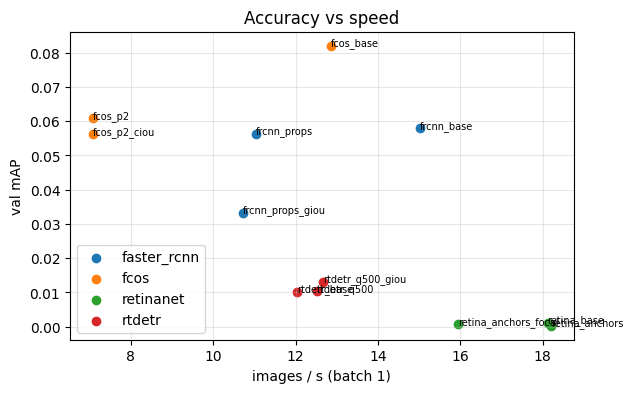

In [36]:
ALL_RES = {**frcnn_res, **retina_res, **fcos_res, **rtdetr_res}
if ALL_RES:
    summary = hd.results_table(list(ALL_RES.values()))
    display(summary)
    display(hd.per_class_table(list(ALL_RES.values())))
    fig, ax = plt.subplots(figsize=(6.5, 4))
    for arch, g in summary.groupby("arch"):
        ax.scatter(g["fps"], g["mAP"], label=arch)
        for name, r in g.iterrows():
            ax.annotate(name, (r["fps"], r["mAP"]), fontsize=7)
    ax.set_xlabel("images / s (batch 1)")
    ax.set_ylabel("val mAP")
    ax.set_title("Accuracy vs speed")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    summary.to_csv(RESULTS_DIR / "summary_required_models.csv")

## 8. Baseline submission
Predictions of the best required model (by validation mAP) on the test set — a valid submission to check the
format and beat the baseline early. It is not the final pipeline.

In [14]:
if MAKE_SUBMISSION and ALL_RES:
    best = best_of(ALL_RES)
    print("model:", best["name"], "| val mAP", round(best["mAP"], 4))
    model = hd.load_model_from_run(run_dir(best["name"]), DEVICE)
    with open(run_dir(best["name"]) / "config.json") as f:
        best_cfg = json.load(f)
    test_preds = hd.predict_df(model, test_df, best_cfg, DEVICE)
    sub_path = WORK_DIR / f"submission_{best['name']}.csv"
    hd.make_submission(test_df, test_preds, sub_path, max_det=500)
    reference = next(DATA_ROOT.glob("sample_submission*.csv"), DATA_ROOT / "test_images.csv")
    print(hd.validate_submission(sub_path, reference))
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

## 9. Your pipeline
*To be done later: data / inference strategy experiments and model experiments, built on the results above.*